In [7]:
# Libraries Needed

import numpy as np
import matplotlib.pyplot as plt 
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from time import time


In [8]:
# Sample Data
np.random.seed(42)
# Input To Model
X = 2 * np.random.rand(100, 1)
# Output From Model
y = 4 + 3 * X + np.random.randn(100, 1)


In [9]:
class PureLoopLinearRegression : 
    def __init__(self):
        self.coefficient = None
        self.intercept = None
        
    def fit(self, X, y, learning_rate = 0.01, n_iterations=1000):
        n_samples = len(y)
        self.coefficient = 0
        self.intercept = 0
        
        for _ in range(n_iterations):
            y_pred = [self.predict(x) for x in X]
            
            # Calculate Gradients
            gradient_intercept = 0
            gradient_coefficient = 0
            
            for i in range(n_samples):
                gradient_intercept += 2 * (y_pred[i] - y[i])
                gradient_coefficient += 2 * X[i] * (y_pred[i] - y[i])
                
            gradient_intercept /= n_samples
            gradient_coefficient /= n_samples
            
            # Update Parameters
            self.intercept -= learning_rate * gradient_intercept
            self.coefficient -= learning_rate * gradient_coefficient
            
    def predict(self, x) : 
        return self.intercept + self.coefficient * x
            

In [10]:
# Predictions Using Pure Model
pure_model = PureLoopLinearRegression()
pure_model.fit(X, y)   # درب النموذج على الداتا اللي حضرتها
X_new = np.array([[0], [2]])
y_predict_pure = [pure_model.predict(x[0]) for x in X_new]

In [11]:
# Scikit-Learn Model
start_time = time()
sklearn_model = LinearRegression()
sklearn_model.fit(X, y)
scikit_learn_time = time() - start_time

In [12]:
# Predictions Using sklearn model
y_predict_sklearn = sklearn_model.predict(X_new)


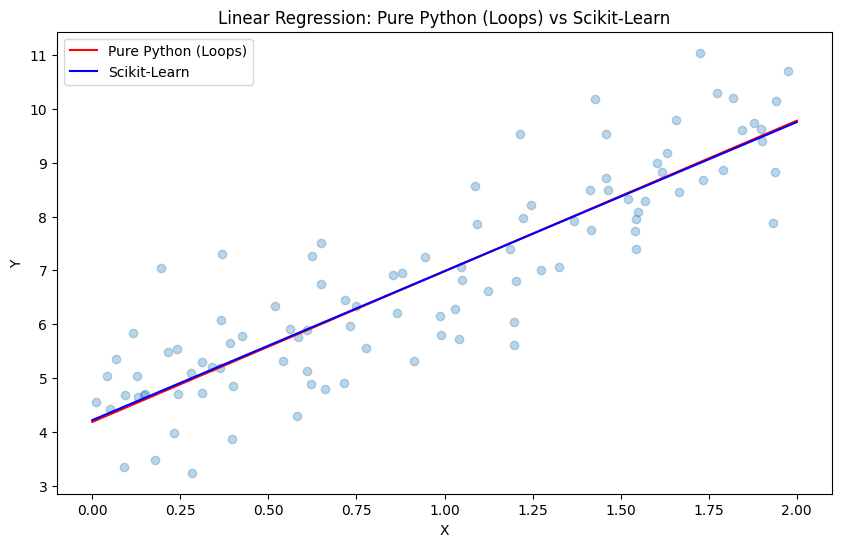

In [13]:
# Plotting Results
plt.figure(figsize=(10, 6))
plt.scatter(X, y, alpha=0.3)
plt.plot(X_new, y_predict_pure, 'r-', label='Pure Python (Loops)')
plt.plot(X_new, y_predict_sklearn, 'b-', label='Scikit-Learn')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.title('Linear Regression: Pure Python (Loops) vs Scikit-Learn')
plt.show()


In [15]:
# تدريب النموذج اليدوي (Pure Python Loops)
start = time()
pure_model = PureLoopLinearRegression()
pure_model.fit(X, y)
pure_python_time = time() - start

# تدريب نموذج Scikit-Learn
start = time()
sk_model = LinearRegression()
sk_model.fit(X, y)
scikit_learn_time = time() - start

# مقارنة الزمن
print(f"Pure Python (Loops) Execution Time : {pure_python_time:.6f} Seconds")
print(f"Scikit-Learn Execution Time        : {scikit_learn_time:.6f} Seconds")
print(f"Scikit-Learn is {pure_python_time / scikit_learn_time:.2f}x faster")


Pure Python (Loops) Execution Time : 0.707952 Seconds
Scikit-Learn Execution Time        : 0.001862 Seconds
Scikit-Learn is 380.25x faster


In [16]:
# Compare Code Complexity
print(f"Lines Of Code For Pure Python Implementation : 30")
print(f"Lines Of Code For Scikit-Learn Implementation : 2")

Lines Of Code For Pure Python Implementation : 30
Lines Of Code For Scikit-Learn Implementation : 2


In [18]:
from sklearn.metrics import mean_squared_error, r2_score

# مخرجات النماذج
y_pred_pure = [pure_model.predict(x[0]) for x in X]
y_pred_sklearn = sklearn_model.predict(X)

# حساب الأخطاء
mse_pure = mean_squared_error(y, y_pred_pure)
mse_sklearn = mean_squared_error(y, y_pred_sklearn)

r2_pure = r2_score(y, y_pred_pure)
r2_sklearn = r2_score(y, y_pred_sklearn)

# عرض النتائج
print(f"Mean Squared Error (Pure Python - Loops) : {mse_pure:.6f}")
print(f"Mean Squared Error (Scikit-Learn)        : {mse_sklearn:.6f}")
print(f"R-Squared (Pure Python - Loops)          : {r2_pure:.6f}")
print(f"R-Squared (Scikit-Learn)                 : {r2_sklearn:.6f}")


Mean Squared Error (Pure Python - Loops) : 0.806917
Mean Squared Error (Scikit-Learn)        : 0.806585
R-Squared (Pure Python - Loops)          : 0.769178
R-Squared (Scikit-Learn)                 : 0.769274
